In [14]:
from rowland_geometry import Analyzer, ReferenceFrame, RowlandSpectrometer
import numpy as np

symm_sbca = Analyzer(
    material = 'Si',
    reflection = [5,3,1],
    cut = [5,3,1],
    bending_radius = 500,
)

# alpha is ~15 deg
asym_sbca = Analyzer(
    material = 'Si',
    reflection = [5,3,1],
    cut = [2,1,1],
    bending_radius = 500,
)

bragg_angles = [85, 75, 65]

delta = 0.1
fan_angles = np.arange(-32.5, 32.5 + delta, delta)


In [17]:
# Arrays for the z-offset when revolving about the axis from source to meridional focus
symm_fm_z_offs = []
asym_fm_z_offs = []

# Arrays for the z-offset when revolving about the axis from source to sagittal focus
symm_fs_z_offs = []
asym_fs_z_offs = []

for bragg in bragg_angles:

    symm_fm_z_off = []
    asym_fm_z_off = []
    symm_fs_z_off = []
    asym_fs_z_off = []

    symm_reference = RowlandSpectrometer(
        analyzer=symm_sbca,
        bragg=bragg,
        frame=ReferenceFrame(origin="source", axis_element="analyzer", axis="x")
    )

    asym_reference = RowlandSpectrometer(
        analyzer=asym_sbca,
        bragg=bragg,
        frame=ReferenceFrame(origin="source", axis_element="analyzer", axis="x")
    )

    symm_y0 = symm_reference.coords_reference_frame()["analyzer"][1]
    asym_y0 = asym_reference.coords_reference_frame()["analyzer"][1]

    for fan_angle in fan_angles:

        meridional_focusing = ReferenceFrame(
            origin="source",
            axis_element="analyzer",
            axis = "x",
            out_of_plane_rotation= fan_angle,
            out_of_plane_axis="meridional"
        )

        sagittal_focusing = ReferenceFrame(
            origin="source",
            axis_element="analyzer",
            axis = "x",
            out_of_plane_rotation= fan_angle,
            out_of_plane_axis="sagittal"
        )

        symm_meridional = RowlandSpectrometer(
            analyzer=symm_sbca,
            bragg = bragg,
            frame = meridional_focusing
        )

        symm_sagittal = RowlandSpectrometer(
            analyzer=symm_sbca,
            bragg = bragg,
            frame = sagittal_focusing
        )

        asym_meridional = RowlandSpectrometer(
            analyzer=asym_sbca,
            bragg = bragg,
            frame = meridional_focusing
        )

        asym_sagittal = RowlandSpectrometer(
            analyzer=asym_sbca,
            bragg = bragg,
            frame = sagittal_focusing
        )

        symm_fm_z_off.append(
            symm_meridional.coords_reference_frame()["analyzer"][1] - symm_y0
        )

        asym_fm_z_off.append(
            asym_meridional.coords_reference_frame()["analyzer"][1] - asym_y0
        )

        symm_fs_z_off.append(
            symm_sagittal.coords_reference_frame()["analyzer"][1] - symm_y0
        )

        asym_fs_z_off.append(
            asym_sagittal.coords_reference_frame()["analyzer"][1] - asym_y0
        )

    # Store results for each Bragg angle
    symm_fm_z_offs.append(symm_fm_z_off)
    asym_fm_z_offs.append(asym_fm_z_off)
    symm_fs_z_offs.append(symm_fs_z_off)
    asym_fs_z_offs.append(asym_fs_z_off)

# Convert to NumPy arrays
symm_fm_z_offs = np.array(symm_fm_z_offs)
asym_fm_z_offs = np.array(asym_fm_z_offs)
symm_fs_z_offs = np.array(symm_fs_z_offs)
asym_fs_z_offs = np.array(asym_fs_z_offs)

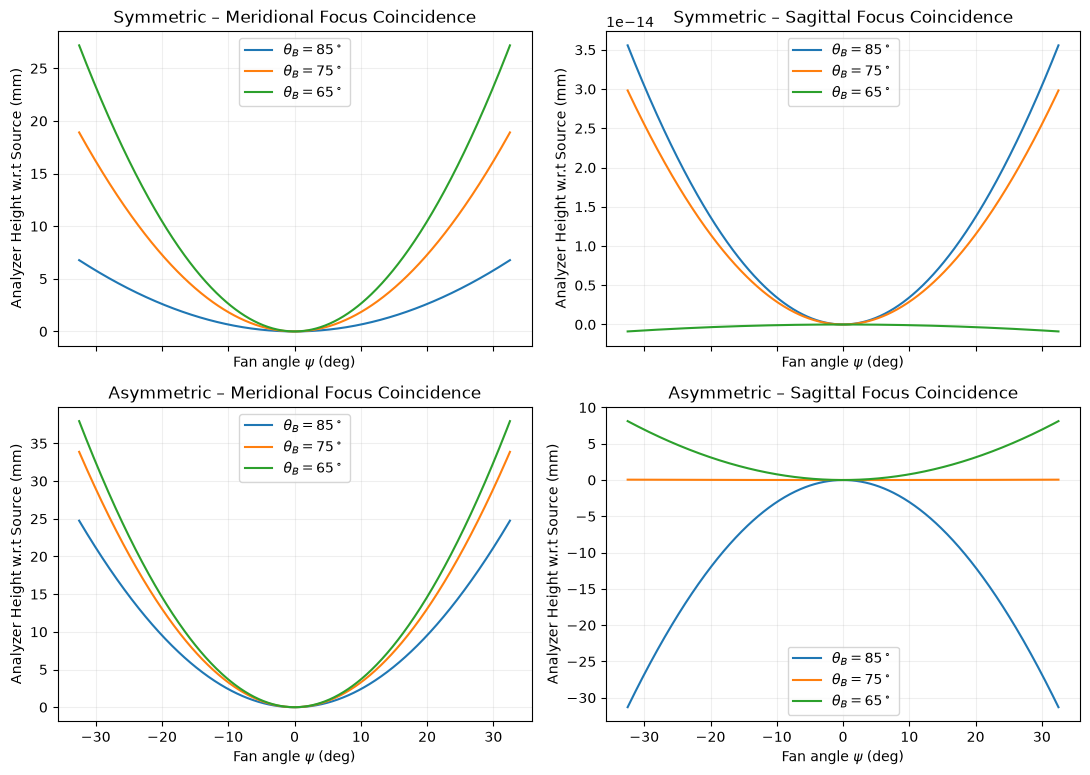

In [20]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True)

datasets = [
    (symm_fm_z_offs, "Symmetric – Meridional Focus Coincidence"),
    (symm_fs_z_offs, "Symmetric – Sagittal Focus Coincidence"),
    (asym_fm_z_offs, "Asymmetric – Meridional Focus Coincidence"),
    (asym_fs_z_offs, "Asymmetric – Sagittal Focus Coincidence"),
]

for ax, (data, title) in zip(axes.flat, datasets):
    for i, bragg in enumerate(bragg_angles):
        ax.plot(
            fan_angles,
            data[i],
            label=fr"$\theta_B = {bragg}^\circ$"
        )

    ax.set_title(title)
    ax.set_xlabel(r"Fan angle $\psi$ (deg)")
    ax.set_ylabel(r"Analyzer Height w.r.t Source (mm)")
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()